# Prétraitement des données

**Objectif.** Cette étape consiste à préparer les **1 000 000 de simulations thermiques** pour l'entraînement et l'évaluation des différents modèles.

Le prétraitement repose sur les quatre partitions définies lors de l'analyse exploratoire : entraînement, validation, test et réserve U. Ces partitions sont conservées afin de garantir une comparaison cohérente entre les expériences.

Les principales opérations comprennent la vérification des données, leur transformation, la normalisation et la sauvegarde des fichiers préparés.

**Les statistiques de normalisation sont calculées uniquement sur l'ensemble d'entraînement**, afin d'éviter toute fuite d'information vers les ensembles d'évaluation.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "quentin_house").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "quentin_house").is_dir():
    raise FileNotFoundError("Dossier quentin_house introuvable.")

sys.path.insert(0, str(ROOT))
from util_assessement import load_single_batch

DATA_DIR = ROOT / "quentin_house"
SPLIT_DIR = ROOT / "data" / "splits"
PREP_DIR = ROOT / "data" / "prepared"
FIGURES_DIR = ROOT / "figures" / "preprocessing"

PREP_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TARGET_NAMES = ["HLC", "HLCext", "HLCmit", "tau_b", "tau_n", "tau_inf"]
INDEPENDENT_TARGETS = TARGET_NAMES[1:]

def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Chargement des partitions

Les quatre partitions définies lors de l'analyse exploratoire sont récupérées depuis le fichier `partitions_1m.npz` : entraînement, validation, test et réserve U.

Les indices des simulations ainsi que leur correspondance avec les fichiers d'origine sont conservés afin de garantir l'utilisation des mêmes données dans toutes les expériences de modélisation.

In [2]:
split_path = SPLIT_DIR / "partitions_1m.npz"
with np.load(split_path, allow_pickle=False) as saved:
    train_idx = saved["train"]
    val_idx = saved["validation"]
    test_idx = saved["test"]
    reserve_idx = saved["reserve_u"]
    row_map = saved["row_map"]

splits = {
    "Train": train_idx,
    "Validation": val_idx,
    "Test": test_idx,
    "Réserve U": reserve_idx
}
N = len(row_map)

for name, idx in splits.items():
    print(f"{name} : {len(idx):,} ({len(idx)/N:.2%})")

Train : 719,885 (71.99%)
Validation : 89,985 (9.00%)
Test : 89,987 (9.00%)
Réserve U : 100,143 (10.01%)


## 2. Vérification de la structure des simulations

Les fichiers de simulations sont identifiés et parcourus dans leur ordre numérique. Un premier lot est chargé afin de vérifier les dimensions des séries de température $T(t)$ et de sollicitation thermique $U(t)$.

L'ordre des composantes de déperdition thermique est également examiné afin de garantir l'association correcte des variables cibles lors du prétraitement.

In [3]:
batch_files = sorted(
    DATA_DIR.rglob("batch_*.pt"),
    key=lambda f: int(f.stem.split("_")[-1])
)
if not batch_files:
    raise FileNotFoundError("Aucun batch trouvé.")

b = load_single_batch(batch_files[0])
T_example = b.indoor_temperature[0].numpy().copy()
U_example = b.indoor_U[0].numpy().copy()

print("Nombre de batchs :", len(batch_files))
print("Température :", b.indoor_temperature.shape)
print("Sollicitation :", b.indoor_U.shape)
print("Composantes Hb :", b.Hb_labels)

Nombre de batchs : 20
Température : torch.Size([50000, 480])
Sollicitation : torch.Size([50000, 480])
Composantes Hb : ['HLC_mit', 'HLC_ext']


### 3. Lecture d’un premier batch

Nous examinons les formes des séries temporelles et les noms des composantes thermiques. Le chargement des fichiers dans l'ordre numérique garantit la correspondance avec les indices de l'EDA.

In [4]:
def extract_features(T, U, segments=8):
    T = np.asarray(T, dtype=np.float64)
    U = np.asarray(U, dtype=np.float64)
    assert T.shape == U.shape and T.ndim == 2 and T.shape[1] == 480

    n, length = T.shape
    dt = np.diff(T, axis=1)
    active = U != 0
    changes = active[:, 1:] != active[:, :-1]

    # Durées des périodes actives et inactives
    starts = np.concatenate([np.ones((n, 1), dtype=bool), changes], axis=1)
    ends = np.concatenate([changes, np.ones((n, 1), dtype=bool)], axis=1)
    positions = np.broadcast_to(np.arange(length), (n, length))
    last_start = np.maximum.accumulate(np.where(starts, positions, 0), axis=1)
    run_lengths = positions - last_start + 1

    on_runs = (starts & active).sum(axis=1)
    off_runs = (starts & ~active).sum(axis=1)
    on_mean = np.divide(active.sum(axis=1), on_runs,
                        out=np.zeros(n), where=on_runs > 0)
    off_mean = np.divide((~active).sum(axis=1), off_runs,
                         out=np.zeros(n), where=off_runs > 0)
    on_max = np.where(ends & active, run_lengths, 0).max(axis=1)
    off_max = np.where(ends & ~active, run_lengths, 0).max(axis=1)

    any_active = active.any(axis=1)
    first_active = np.where(any_active, active.argmax(axis=1) / (length - 1), -1)
    last_active = np.where(any_active,
                           1 - active[:, ::-1].argmax(axis=1) / (length - 1), -1)

    values = {
        "T_initial": T[:, 0],
        "T_final": T[:, -1],
        "T_mean": T.mean(axis=1),
        "T_std": T.std(axis=1),
        "T_min": T.min(axis=1),
        "T_max": T.max(axis=1),
        "T_total_variation": np.abs(dt).sum(axis=1),
        "dT_std": dt.std(axis=1),
        "dT_min": dt.min(axis=1),
        "dT_max": dt.max(axis=1),
        "T_rising_fraction": (dt > 0).mean(axis=1),
        "U_initial": U[:, 0],
        "U_final": U[:, -1],
        "U_mean": U.mean(axis=1),
        "U_std": U.std(axis=1),
        "U_min": U.min(axis=1),
        "U_max": U.max(axis=1),
        "U_active_fraction": active.mean(axis=1),
        "U_switches": changes.sum(axis=1),
        "U_on_switches": (changes & active[:, 1:]).sum(axis=1),
        "U_off_switches": (changes & ~active[:, 1:]).sum(axis=1),
        "U_on_run_mean": on_mean,
        "U_on_run_max": on_max,
        "U_off_run_mean": off_mean,
        "U_off_run_max": off_max,
        "U_first_active_index_fraction": first_active,
        "U_last_active_index_fraction": last_active
    }

    # Résumés sur huit parties de la série
    for i, indices in enumerate(np.array_split(np.arange(length), segments)):
        start, stop = indices[0], indices[-1] + 1
        values[f"segment_{i}_T_mean"] = T[:, start:stop].mean(axis=1)
        values[f"segment_{i}_T_change"] = T[:, stop - 1] - T[:, start]
        values[f"segment_{i}_U_mean"] = U[:, start:stop].mean(axis=1)
        values[f"segment_{i}_U_active_fraction"] = active[:, start:stop].mean(axis=1)

    X = np.column_stack(list(values.values())).astype(np.float32)
    assert X.shape == (n, 59) and np.isfinite(X).all()
    return X, list(values)

## 4. Extraction des caractéristiques statistiques

Les séries temporelles de température intérieure $T(t)$ et de sollicitation thermique $U(t)$ sont transformées en **59 caractéristiques statistiques** afin de résumer les principales informations contenues dans les signaux.

Ces caractéristiques décrivent notamment :

- **La température :** valeurs moyennes, extrêmes, dispersion et variations temporelles.
- **La sollicitation thermique :** intensité, périodes actives et inactives, nombre de transitions et durées associées.
- **L'évolution temporelle :** statistiques calculées sur huit segments successifs pour conserver une information sur la dynamique des signaux.

Cette extraction permet d'obtenir une représentation synthétique de chaque simulation, destinée notamment à l'entraînement du MLP.

Les caractéristiques sont calculées exclusivement à partir des signaux observés, sans utiliser les paramètres thermiques à prédire.

In [5]:
X_demo, feature_names = extract_features(T_example[None, :], U_example[None, :])
print("Caractéristiques :", len(feature_names))
display(pd.DataFrame({"Caractéristique": feature_names, "Valeur": X_demo[0]}))

Caractéristiques : 59


,Caractéristique,Valeur
0,T_initial,24.624001
1,T_final,32.630810
2,T_mean,32.043457
3,T_std,5.032312
4,T_min,24.624001
5,T_max,38.138554
6,T_total_variation,19.022297
7,dT_std,0.079206
8,dT_min,-0.434528
9,dT_max,0.448753


## 5. Préparation des fichiers de données

Les données sont organisées en trois fichiers : `sequences.npy` pour les séries temporelles, `features.npy` pour les caractéristiques statistiques et `targets.npy` pour les indicateurs thermiques.

Les fichiers existants sont réutilisés afin d'éviter de répéter les calculs. Leur reconstruction peut être activée lorsque les données ou les méthodes de prétraitement sont modifiées.

In [6]:
SEQUENCE_PATH = PREP_DIR / "sequences.npy"
FEATURE_PATH = PREP_DIR / "features.npy"
TARGET_PATH = PREP_DIR / "targets.npy"
CHUNK_SIZE = 1024

cache_files = [SEQUENCE_PATH, FEATURE_PATH, TARGET_PATH]
REBUILD_CACHE = False
create_cache = REBUILD_CACHE or not all(path.exists() for path in cache_files)

print("Préparer les tableaux :", create_cache)

Préparer les tableaux : False


## 6. Allocation des tableaux de données

Les données préparées sont organisées en trois tableaux NumPy contenant les séries temporelles, les caractéristiques statistiques et les variables cibles.

L'allocation utilise le **mappage mémoire (*memory mapping*)**, permettant d'écrire progressivement les données sur disque sans charger l'ensemble des simulations en mémoire vive.

Les tableaux sont enregistrés au format `float32` pour limiter l'espace de stockage.

In [7]:
if create_cache:
    sequences = np.lib.format.open_memmap(
        SEQUENCE_PATH, mode="w+", dtype=np.float32, shape=(N, 2, 480)
    )
    features = np.lib.format.open_memmap(
        FEATURE_PATH, mode="w+", dtype=np.float32, shape=(N, 59)
    )
    targets = np.lib.format.open_memmap(
        TARGET_PATH, mode="w+", dtype=np.float32, shape=(N, 6)
    )

### 7. Création des tableaux sur disque

Nous utilisons des tableaux NumPy directement sur disque. Cette méthode permet de traiter un million de simulations par blocs, sans conserver toutes les séries en mémoire vive.

In [8]:
if create_cache:
    offset = 0

    for file in batch_files:
        print("Batch :", file.name)
        b = load_single_batch(file)
        n = len(b.HLC)
        batch_id = int(file.stem.split("_")[-1])

        rows = row_map[offset:offset + n]
        if not (len(rows) == n and
                np.all(rows[:, 0] == batch_id) and
                np.array_equal(rows[:, 1], np.arange(n))):
            raise ValueError(f"Ordre différent de l'EDA : {file.name}")

        assert b.indoor_temperature.shape == (n, 480)
        assert b.indoor_U.shape == (n, 480)
        assert b.Hb.shape == (n, 2)
        assert b.CDT.shape == (n, 3)

        labels = [str(s).lower().replace("_", "").replace(" ", "")
                  for s in b.Hb_labels]
        ext_col = labels.index("hlcext")
        mit_col = labels.index("hlcmit")

        for start in range(0, n, CHUNK_SIZE):
            stop = min(start + CHUNK_SIZE, n)
            T = b.indoor_temperature[start:stop].numpy()
            U = b.indoor_U[start:stop].numpy()

            x = np.stack([T, U], axis=1).astype(np.float32)
            y = np.column_stack([
                b.HLC[start:stop].reshape(-1).numpy(),
                b.Hb[start:stop, ext_col].numpy(),
                b.Hb[start:stop, mit_col].numpy(),
                b.CDT[start:stop].numpy()
            ]).astype(np.float32)
            f, names = extract_features(T, U)

            if not np.isfinite(x).all() or not np.isfinite(y).all():
                raise ValueError(f"Valeurs invalides dans {file.name}")
            if not np.allclose(y[:, 0], y[:, 1] + y[:, 2], rtol=1e-5, atol=1e-4):
                raise ValueError(f"Relation HLC non respectée dans {file.name}")

            a, z = offset + start, offset + stop
            sequences[a:z] = x
            features[a:z] = f
            targets[a:z] = y

        offset += n
        sequences.flush()
        features.flush()
        targets.flush()

    if offset != N:
        raise ValueError("Le nombre de simulations ne correspond pas à l'EDA.")

### 8. Préparation des batchs

Nous lisons chaque batch dans l'ordre, puis traitons les simulations par blocs de 1 024. Pour chaque ligne, nous conservons les séries `(T, U)`, les 59 caractéristiques et les six paramètres thermiques. Avant l'enregistrement, nous vérifions l'ordre des lignes et la relation physique du HLC.

In [9]:
if create_cache:
    sequences.flush()
    features.flush()
    targets.flush()

print("Tableaux prêts.")

Tableaux prêts.


### 9. Enregistrement des données préparées

Nous terminons l'écriture des trois tableaux. Aucun fichier CSV ni fichier de suivi du cache n'est nécessaire à cette étape.

In [10]:
sequences = np.load(SEQUENCE_PATH, mmap_mode="r", allow_pickle=False)
features = np.load(FEATURE_PATH, mmap_mode="r", allow_pickle=False)
targets = np.load(TARGET_PATH, mmap_mode="r", allow_pickle=False)

if sequences.shape != (N, 2, 480) or features.shape != (N, 59) or targets.shape != (N, 6):
    raise ValueError("Cache incompatible. Mettre REBUILD_CACHE = True pour le recréer.")

print("Séries :", sequences.shape)
print("Caractéristiques :", features.shape)
print("Cibles :", targets.shape)

Séries : (1000000, 2, 480)
Caractéristiques : (1000000, 59)
Cibles : (1000000, 6)


### 10. Ouverture des tableaux

Nous ouvrons les fichiers préparés sans les charger intégralement en mémoire. Ils suivent tous le même ordre de simulations défini par `row_map`.

In [11]:
def fit_moments(array, indices, columns=None, chunk_size=2048):
    indices = np.sort(np.asarray(indices))
    count = 0
    mean, m2 = None, None

    for start in range(0, len(indices), chunk_size):
        block = np.asarray(array[indices[start:start + chunk_size]], dtype=np.float64)
        if columns is not None:
            block = block[:, columns]
        assert np.isfinite(block).all()

        n = len(block)
        block_mean = block.mean(axis=0)
        block_m2 = ((block - block_mean) ** 2).sum(axis=0)

        if mean is None:
            mean, m2, count = block_mean, block_m2, n
        else:
            delta = block_mean - mean
            new_count = count + n
            m2 += block_m2 + delta ** 2 * count * n / new_count
            mean += delta * n / new_count
            count = new_count

    return mean, np.sqrt(np.maximum(m2 / count, 0))

### 11. Calcul des statistiques sur l’entraînement

Nous calculons les moyennes et les écarts-types par blocs, afin d'éviter de copier toutes les données en mémoire. Cette fonction est utilisée pour les caractéristiques statistiques et les cibles thermiques.

In [12]:
feature_mean, feature_std = fit_moments(features, train_idx)
active_mask = feature_std > 1e-8
feature_scale = np.where(active_mask, feature_std, 1.0)

retained_features = [name for name, ok in zip(feature_names, active_mask) if ok]
dropped_features = [name for name, ok in zip(feature_names, active_mask) if not ok]

print("Caractéristiques calculées :", len(feature_names))
print("Caractéristiques retenues :", len(retained_features))
print("Caractéristiques constantes :", dropped_features)

display(pd.DataFrame({
    "Caractéristique": feature_names,
    "Moyenne train": feature_mean,
    "Écart-type train": feature_std,
    "Retenue": active_mask
}).round(4))

Caractéristiques calculées : 59
Caractéristiques retenues : 58
Caractéristiques constantes : ['T_initial']


,Caractéristique,Moyenne train,Écart-type train,Retenue
0,T_initial,24.6240,0.0000,False
1,T_final,32.8701,4.8703,True
2,T_mean,30.5547,2.7576,True
3,T_std,3.5859,1.6151,True
4,T_min,24.6189,0.0168,True
5,T_max,35.9382,4.0191,True
6,T_total_variation,23.5089,18.5765,True
7,dT_std,0.0816,0.0445,True
8,dT_min,-0.2569,0.2042,True
9,dT_max,0.4097,0.1277,True


### 12. Caractéristiques retenues pour le MLP

Nous standardisons les caractéristiques à partir des données d'entraînement. Les variables dont l'écart-type est inférieur ou égal à $10^{-8}$ sont écartées à l'entrée du MLP, car elles ne varient pratiquement pas.

In [13]:
def fit_signal_moments(sequences, indices, chunk_size=1024):
    indices = np.sort(np.asarray(indices))
    count = 0
    mean = np.zeros(2, dtype=np.float64)
    m2 = np.zeros(2, dtype=np.float64)

    for start in range(0, len(indices), chunk_size):
        block = np.asarray(sequences[indices[start:start + chunk_size]], dtype=np.float64)
        block_mean = block.mean(axis=(0, 2))
        block_m2 = ((block - block_mean[None, :, None]) ** 2).sum(axis=(0, 2))

        n = len(block) * block.shape[2]
        delta = block_mean - mean
        new_count = count + n
        m2 += block_m2 + delta ** 2 * count * n / new_count
        mean += delta * n / new_count
        count = new_count

    return mean, np.sqrt(np.maximum(m2 / count, 0))

### 13. Statistiques des séries temporelles

Nous calculons séparément les statistiques globales des deux canaux, température et sollicitation, sur l'ensemble des instants des simulations d'entraînement.

In [14]:
channel_mean, channel_std = fit_signal_moments(sequences, train_idx)
T_mean = float(channel_mean[0])
T_std = float(channel_std[0])
U_RMS = float(np.sqrt(channel_std[1] ** 2 + channel_mean[1] ** 2))

assert T_std > 0 and U_RMS > 0
print("Température — moyenne :", T_mean)
print("Température — écart-type :", T_std)
print("Sollicitation — RMS :", U_RMS)

Température — moyenne : 30.55474841200245
Température — écart-type : 4.803293081437178
Sollicitation — RMS : 4791.073515544674


### 14. Échelles pour les modèles temporels

Nous centrons et réduisons la température avec sa moyenne et son écart-type d'entraînement. Nous divisons la sollicitation par sa valeur RMS, sans la centrer, afin de conserver les instants où `U = 0`.

In [15]:
target_mean, target_std = fit_moments(targets, train_idx, columns=slice(1, None))

display(pd.DataFrame({
    "Cible": INDEPENDENT_TARGETS,
    "Moyenne train": target_mean,
    "Écart-type train": target_std
}).round(4))

,Cible,Moyenne train,Écart-type train
0,HLCext,112.4524,17.1204
1,HLCmit,120.5240,26.2386
2,tau_b,49.9917,10.0901
3,tau_n,11.0384,2.0074
4,tau_inf,31.2252,7.5243


### 15. Statistiques des cibles

Nous calculons les statistiques des cinq cibles indépendantes sur l'entraînement. Les cibles restent en unités physiques dans les fonctions de préparation des lots ; ces statistiques pourront être utilisées lors de l'apprentissage.

In [16]:
PREPROCESSING_PATH = PREP_DIR / "preprocessing.json"

preprocessing = {
    "dataset_rows": int(N),
    "fit_partition": "train",
    "train_rows": int(len(train_idx)),
    "feature_names": feature_names,
    "feature_mean": feature_mean.tolist(),
    "feature_std": feature_scale.tolist(),
    "active_mask": active_mask.tolist(),
    "retained_features": retained_features,
    "dropped_features": dropped_features,
    "signal_scaling": {
        "T_mean": T_mean,
        "T_std": T_std,
        "U_center": 0.0,
        "U_RMS": U_RMS
    },
    "independent_target_names": INDEPENDENT_TARGETS,
    "target_mean": target_mean.tolist(),
    "target_std": target_std.tolist(),
    "physical_constraint": "HLC = HLCext + HLCmit"
}

with open(PREPROCESSING_PATH, "w", encoding="utf-8") as file:
    json.dump(preprocessing, file, indent=2)

print("Paramètres de normalisation enregistrés.")

Paramètres de normalisation enregistrés.


### 16. Conservation des paramètres de normalisation

Nous enregistrons dans `preprocessing.json` les statistiques et le masque des caractéristiques. Ce fichier est utile pour appliquer les mêmes transformations à la validation, au test et à la réserve, puis lors de l'utilisation des modèles.

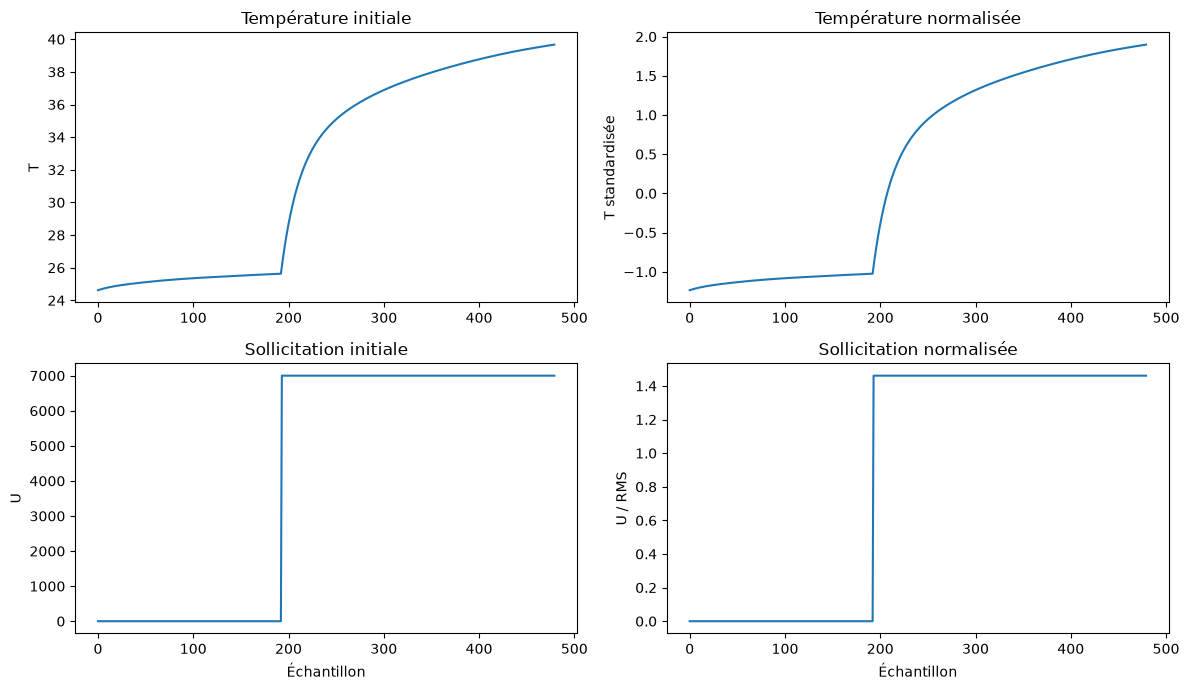

In [17]:
sample_id = int(train_idx[0])
raw_signal = np.asarray(sequences[sample_id], dtype=np.float32).copy()
normalized_signal = raw_signal.copy()
normalized_signal[0] = (normalized_signal[0] - T_mean) / T_std
normalized_signal[1] = normalized_signal[1] / U_RMS

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(raw_signal[0])
axes[0, 0].set(title="Température initiale", ylabel="T")
axes[0, 1].plot(normalized_signal[0])
axes[0, 1].set(title="Température normalisée", ylabel="T standardisée")
axes[1, 0].plot(raw_signal[1])
axes[1, 0].set(title="Sollicitation initiale", xlabel="Échantillon", ylabel="U")
axes[1, 1].plot(normalized_signal[1])
axes[1, 1].set(title="Sollicitation normalisée", xlabel="Échantillon", ylabel="U / RMS")

plt.tight_layout()
save_figure(fig, "01_avant_apres_normalisation")
plt.show()

### 17. Effet de la normalisation

Nous comparons une série brute et sa version normalisée. La transformation ne modifie pas la chronologie des signaux ; les valeurs nulles de sollicitation restent nulles.

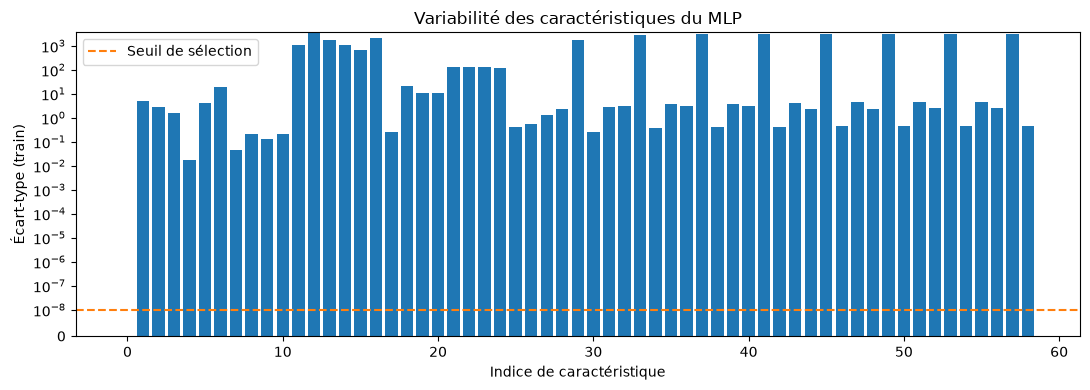

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(feature_std)), feature_std)
ax.axhline(1e-8, color="tab:orange", linestyle="--", label="Seuil de sélection")
ax.set_yscale("symlog", linthresh=1e-8)
ax.set(title="Variabilité des caractéristiques du MLP",
       xlabel="Indice de caractéristique", ylabel="Écart-type (train)")
ax.legend()

plt.tight_layout()
save_figure(fig, "02_variabilite_caracteristiques")
plt.show()

### 18. Variabilité des caractéristiques

Nous représentons les écarts-types calculés sur l'entraînement. Le seuil visible sur le graphique correspond au critère employé pour retenir les caractéristiques du MLP.

In [19]:
def get_mlp_batch(indices):
    indices = np.asarray(indices, dtype=np.int64)
    x = np.asarray(features[indices], dtype=np.float32)
    mean = np.asarray(preprocessing["feature_mean"], dtype=np.float32)
    scale = np.asarray(preprocessing["feature_std"], dtype=np.float32)
    mask = np.asarray(preprocessing["active_mask"], dtype=bool)

    x = (x - mean) / scale
    x = x[:, mask]
    y = np.asarray(targets[indices, 1:], dtype=np.float32)
    return x, y

example_indices = train_idx[:32]
X_mlp, Y_mlp = get_mlp_batch(example_indices)
print("MLP :", X_mlp.shape, "— cibles :", Y_mlp.shape)

MLP : (32, 58) — cibles : (32, 5)


### 19. Préparation des lots MLP

Nous obtenons les caractéristiques standardisées et filtrées, associées aux cinq cibles indépendantes. Les valeurs des cibles ne sont pas normalisées dans cette fonction, conformément à notre prétraitement initial.

In [20]:
def get_temporal_batch(indices):
    indices = np.asarray(indices, dtype=np.int64)
    x = np.asarray(sequences[indices], dtype=np.float32).copy()
    x[:, 0, :] = (x[:, 0, :] - T_mean) / T_std
    x[:, 1, :] = x[:, 1, :] / U_RMS
    y = np.asarray(targets[indices, 1:], dtype=np.float32)
    return x, y

X_temporal, Y_temporal = get_temporal_batch(example_indices)
print("Temporel :", X_temporal.shape, "— cibles :", Y_temporal.shape)

Temporel : (32, 2, 480) — cibles : (32, 5)


### 20. Préparation des lots temporels

Nous conservons les deux signaux sous la forme `(N, 2, 480)`. Les mêmes indices et les mêmes cibles sont utilisés pour tous les modèles, afin de permettre une comparaison équitable.

In [21]:
all_indices = np.concatenate(list(splits.values()))
assert len(all_indices) == N
assert np.array_equal(np.sort(all_indices), np.arange(N))
assert row_map.shape == (N, 2)
assert len(np.unique(row_map, axis=0)) == N
assert sequences.shape == (N, 2, 480)
assert features.shape == (N, 59)
assert targets.shape == (N, 6)

assert X_mlp.shape == (len(example_indices), int(active_mask.sum()))
assert X_temporal.shape == (len(example_indices), 2, 480)
assert Y_mlp.shape == Y_temporal.shape == (len(example_indices), 5)
assert np.array_equal(Y_mlp, Y_temporal)
assert np.isfinite(X_mlp).all() and np.isfinite(X_temporal).all()
assert np.isfinite(Y_mlp).all() and np.all(feature_scale > 0)
assert T_std > 0 and U_RMS > 0 and np.all(target_std > 0)

HLC_reconstructed = Y_mlp[:, 0] + Y_mlp[:, 1]
HLC_original = np.asarray(targets[example_indices, 0], dtype=np.float32)
assert np.allclose(HLC_reconstructed, HLC_original, rtol=1e-5, atol=1e-4)

print("Partitions, données et normalisation vérifiées.")

Partitions, données et normalisation vérifiées.


### 21. Vérifications finales

Nous vérifions la couverture des partitions, l'alignement des tableaux, les valeurs finies, les dimensions des lots et la reconstruction du HLC. Les contrôles détaillés sont regroupés ici, après les analyses principales.